# AI651 Assignment 2, Question 2: Motion or Memory?

Everything for Q2 is in this one notebook. Run it top to bottom on a GPU (Colab: Runtime > Change runtime type > T4 GPU).
Trained weights and result files get saved to Google Drive so a disconnect doesn't lose anything.

In [1]:
# setup. on colab this mounts drive so checkpoints survive disconnects
import os, time, json, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/ai651_q2'
except ImportError:
    OUT = './q2_out'   # running locally

os.makedirs(OUT, exist_ok=True)
os.makedirs(f'{OUT}/ckpt', exist_ok=True)
os.makedirs(f'{OUT}/figs', exist_ok=True)
os.makedirs(f'{OUT}/gifs', exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Mounted at /content/drive
device: cuda Tesla T4


## 1. Setup
### Data
The full dataset is 10,000 videos x 20 frames x 1 x 64 x 64 (uint8). I keep it as uint8 (about 800 MB) and
only turn a batch into float32 / 255 when it is used, otherwise it would be 3.3 GB in float.
Split by video index: 0-7999 train, 8000-8999 val, 9000-9999 test.

In [2]:
from torchvision.datasets import MovingMNIST

ds = MovingMNIST(root='./data', split=None, download=True)
videos = ds.data              # (10000, 20, 1, 64, 64) uint8
print(videos.shape, videos.dtype)

train_vids = videos[:8000]
val_vids = videos[8000:9000]
test_vids = videos[9000:]
print(len(train_vids), len(val_vids), len(test_vids))


def to_float(v):
    # uint8 -> float in [0, 1]
    return v.float() / 255.0

100%|██████████| 819M/819M [01:02<00:00, 13.2MB/s]


torch.Size([10000, 20, 1, 64, 64]) torch.uint8
8000 1000 1000


### Transformations
All of these work on the last two dims (rows, cols), so they work the same on a single frame,
a video (T,1,64,64) or a batch (B,T,1,64,64).

A group element is stored as a pair (m, a): first rotate by a*90 degrees anticlockwise, then mirror if m == 1.
So (0, a) is R^a and (1, a) is M R^a, which matches the handout.

In [3]:
def mirror(x):
    # (Mx)[i, j] = x[i, 63 - j]  -> flip the column axis
    return torch.flip(x, dims=(-1,))


def rotate(x, k=1):
    # k quarter turns anticlockwise, same as torch.rot90 with k=1 in the handout
    return torch.rot90(x, k=k, dims=(-2, -1))


# the 8 symmetries of the square
G = [(m, a) for m in (0, 1) for a in range(4)]


def apply_g(x, g):
    m, a = g
    y = rotate(x, a)
    if m == 1:
        y = mirror(y)
    return y


def apply_g_inv(x, g):
    m, a = g
    if m == 1:
        # M R^a undoes itself
        return apply_g(x, g)
    return rotate(x, -a)

### Windows at different speeds
Frames are numbered 1..20 like in the handout. For speed k and start t:
input = t, t+k, ..., t+4k and target = t+5k, ..., t+9k, keeping only target frames <= 20.
The model always makes 5 predictions, so I pad the target up to 5 frames and return a mask
that says which ones are real.

In [4]:
def window_frames(t, k=1):
    inp = [t + i * k for i in range(5)]
    tgt = [t + (5 + i) * k for i in range(5)]
    tgt = [f for f in tgt if f <= 20]
    return inp, tgt


def get_window(video, t, k=1):
    # video: (20, C, H, W). returns X (5,C,H,W), Y padded to (5,C,H,W), mask (5,)
    inp, tgt = window_frames(t, k)
    X = video[[f - 1 for f in inp]]          # -1 because python indexes from 0
    Y = torch.zeros_like(X)
    mask = torch.zeros(5)
    if len(tgt) > 0:
        Y[:len(tgt)] = video[[f - 1 for f in tgt]]
        mask[:len(tgt)] = 1
    return X, Y, mask


def allowed_starts(k, speed_aug):
    if not speed_aug:
        # models A and B: 1x only, all 5 targets have to exist
        assert k == 1
        return list(range(1, 12))
    # models C and D: all 5 inputs and at least 2 targets exist -> t + 6k <= 20
    return list(range(1, 20 - 6 * k + 1))


for k in (1, 2, 3):
    s = allowed_starts(k, True)
    print(f'{k}x speed-aug starts: {s[0]}..{s[-1]}')

1x speed-aug starts: 1..14
2x speed-aug starts: 1..8
3x speed-aug starts: 1..2


### Checking the code (Table 1)
Same functions as the experiments use, run on the two test videos from the handout.

In [5]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)

p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1   # frame 7 (python index), row 10, col 20

def maxdiff(a, b):
    return (a - b).abs().max().item()

def bright(v):
    # (frame, row, col) of the one bright pixel
    idx = (v == 1).nonzero()[0]
    return (idx[0].item(), idx[2].item(), idx[3].item())

def frames_used(t, k):
    # a video where frame f is filled with the value f, so we can just read the numbers back
    v = torch.arange(1, 21).float().view(20, 1, 1, 1).expand(20, 1, 64, 64)
    X, Y, mask = get_window(v, t, k)
    ins = [int(f) for f in X[:, 0, 0, 0]]
    outs = [int(f) for f, m in zip(Y[:, 0, 0, 0], mask) if m > 0]
    return ins, outs

def fmt(fr):
    # 1,2,3,4,5 -> '1-5' when consecutive, else list them
    if fr == list(range(fr[0], fr[-1] + 1)):
        return f'{fr[0]}-{fr[-1]}'
    return ', '.join(str(f) for f in fr)

a = maxdiff(mirror(mirror(x)), x)
b = maxdiff(rotate(x, 4), x)
c = maxdiff(mirror(rotate(mirror(x))), rotate(x, -1))
print('torch.equal:', torch.equal(mirror(mirror(x)), x), torch.equal(rotate(x, 4), x),
      torch.equal(mirror(rotate(mirror(x))), rotate(x, -1)))

rows = [
    ('(a)', 'max|M(M(x)) - x|', '0', f'{a:g}'),
    ('(b)', 'max|R^4(x) - x|', '0', f'{b:g}'),
    ('(c)', 'max|MRM(x) - R^-1(x)|', '0', f'{c:g}'),
    ('(d)', 'bright pixel of M(p)', '(7, 10, 43)', str(bright(mirror(p)))),
    ('(e)', 'bright pixel of R(p)', '(7, 43, 10)', str(bright(rotate(p)))),
]
for name, k, exp in [('(f)', 1, '1-5 / 6-10'), ('(g)', 2, '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19'),
                     ('(h)', 3, '1, 4, 7, 10, 13 / 16, 19')]:
    ins, outs = frames_used(1, k)
    rows.append((name, f'{k}x input / target frames', exp, f'{fmt(ins)} / {fmt(outs)}'))

print(f"{'':4} {'Check':28} {'Expected':38} Yours")
for r in rows:
    print(f'{r[0]:4} {r[1]:28} {r[2]:38} {r[3]}')

# also check every group element is undone by its inverse, the symmetrised model depends on this later
assert all(torch.equal(apply_g_inv(apply_g(x, g), g), x) for g in G)
print('all 8 inverses ok')

torch.equal: True True True
     Check                        Expected                               Yours
(a)  max|M(M(x)) - x|             0                                      0
(b)  max|R^4(x) - x|              0                                      0
(c)  max|MRM(x) - R^-1(x)|        0                                      0
(d)  bright pixel of M(p)         (7, 10, 43)                            (7, 10, 43)
(e)  bright pixel of R(p)         (7, 43, 10)                            (7, 43, 10)
(f)  1x input / target frames     1-5 / 6-10                             1-5 / 6-10
(g)  2x input / target frames     1, 3, 5, 7, 9 / 11, 13, 15, 17, 19     1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h)  3x input / target frames     1, 4, 7, 10, 13 / 16, 19               1, 4, 7, 10, 13 / 16, 19
all 8 inverses ok


### Is the training data already symmetric? (Figure 1)
Farneback flow on the first 50 training videos, all 19 consecutive pairs each = 950 pairs.
Keep a pixel only if it is bright (> 0.2, i.e. > 51 in uint8) in both frames and moves more than 0.5 px.

kept pixels: 103050, median speed: 3.318 px/frame


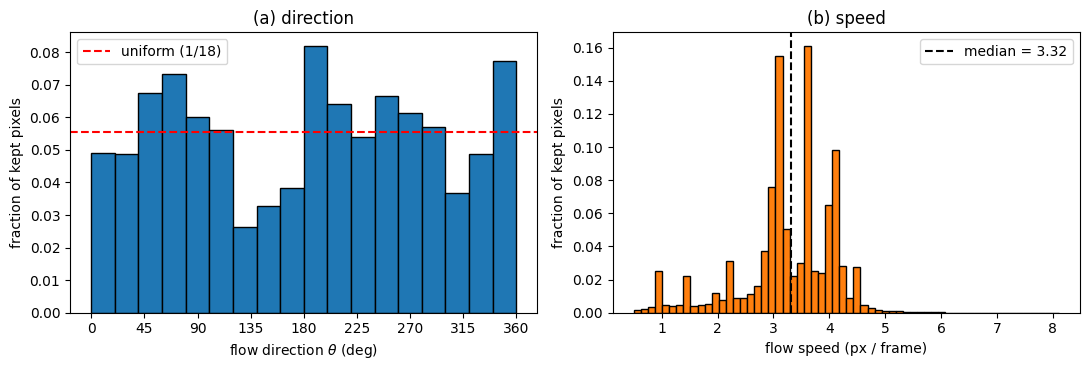

direction fractions per 20 deg bin: [0.049  0.0488 0.0675 0.0731 0.0602 0.0561 0.0263 0.0326 0.0384 0.082
 0.0642 0.0541 0.0666 0.0614 0.0571 0.0366 0.0487 0.0772]
max / min bin vs uniform: 1.476 0.474
total variation, original vs mirrored: 0.1321
total variation, original vs rotated : 0.2
fraction of speeds <= 2x median: 0.9998  <= 3x median: 1.0


In [6]:
import cv2

dx_all, dy_all = [], []
for v in train_vids[:50]:
    fr = v[:, 0].numpy()          # (20, 64, 64) uint8 already, same as float*255
    for s in range(19):
        prev, nxt = fr[s], fr[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        keep = (prev > 51) & (nxt > 51) & (np.sqrt(dx**2 + dy**2) > 0.5)
        dx_all.append(dx[keep])
        dy_all.append(dy[keep])

dx_all = np.concatenate(dx_all)
dy_all = np.concatenate(dy_all)
theta = np.degrees(np.arctan2(-dy_all, dx_all)) % 360   # 0 = right, 90 = up on screen
speed = np.sqrt(dx_all**2 + dy_all**2)
n_kept = len(speed)
med_speed = float(np.median(speed))
print(f'kept pixels: {n_kept}, median speed: {med_speed:.3f} px/frame')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
w = np.ones(n_kept) / n_kept       # so the bars are fractions, not counts
ax[0].hist(theta, bins=np.arange(0, 361, 20), weights=w, edgecolor='k', color='tab:blue')
ax[0].axhline(1 / 18, color='r', ls='--', label='uniform (1/18)')
ax[0].set_xticks(range(0, 361, 45))
ax[0].set_xlabel('flow direction $\\theta$ (deg)')
ax[0].set_ylabel('fraction of kept pixels')
ax[0].set_title('(a) direction')
ax[0].legend()
ax[1].hist(speed, bins=60, weights=w, edgecolor='k', color='tab:orange')
ax[1].axvline(med_speed, color='k', ls='--', label=f'median = {med_speed:.2f}')
ax[1].set_xlabel('flow speed (px / frame)')
ax[1].set_ylabel('fraction of kept pixels')
ax[1].set_title('(b) speed')
ax[1].legend()
plt.tight_layout()
plt.savefig(f'{OUT}/figs/fig1_flow.png', dpi=150)
plt.show()

# a few numbers that help with Q2.1
hist_dir, _ = np.histogram(theta, bins=np.arange(0, 361, 20))
hist_dir = hist_dir / n_kept
print('direction fractions per 20 deg bin:', np.round(hist_dir, 4))
print('max / min bin vs uniform:', round(hist_dir.max() * 18, 3), round(hist_dir.min() * 18, 3))
# mirror sends theta -> 180 - theta, rotation sends theta -> theta + 90. compare the histograms after that
mir = np.histogram((180 - theta) % 360, bins=np.arange(0, 361, 20))[0] / n_kept
rot = np.histogram((theta + 90) % 360, bins=np.arange(0, 361, 20))[0] / n_kept
print('total variation, original vs mirrored:', round(0.5 * np.abs(hist_dir - mir).sum(), 4))
print('total variation, original vs rotated :', round(0.5 * np.abs(hist_dir - rot).sum(), 4))
print('fraction of speeds <= 2x median:', round(float((speed <= 2 * med_speed).mean()), 4),
      ' <= 3x median:', round(float((speed <= 3 * med_speed).mean()), 4))
json.dump({'n_kept': int(n_kept), 'median_speed': med_speed, 'dir_hist': hist_dir.tolist()},
          open(f'{OUT}/fig1_stats.json', 'w'), indent=1)

## 2. Baseline: ConvLSTM (model A)
Written so the same class can be reused for model D later (patch size, kernel, dilation are arguments).
For model A: patch 4, two layers of 64 hidden channels, 3x3 kernels, no peepholes.

In [7]:
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, hid, k=3, dil=1):
        super().__init__()
        self.hid = hid
        pad = dil * (k - 1) // 2       # keeps 16x16 size
        # one conv gives all four gates
        self.conv = nn.Conv2d(cin + hid, 4 * hid, k, padding=pad, dilation=dil, bias=True)

    def forward(self, u, state):
        h, c = state
        i, f, o, g = torch.chunk(self.conv(torch.cat([u, h], dim=1)), 4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTMForecaster(nn.Module):
    def __init__(self, patch=4, hid=(64, 64), k=(3, 3), dil=(1, 1)):
        super().__init__()
        self.patch = patch
        cin = patch * patch                 # 1 channel folded into patch^2 channels
        self.cells = nn.ModuleList()
        for l in range(len(hid)):
            self.cells.append(ConvLSTMCell(cin if l == 0 else hid[l - 1], hid[l], k[l], dil[l]))
        self.out = nn.Conv2d(hid[-1], cin, 1, bias=True)

    def step(self, frame, states):
        u = F.pixel_unshuffle(frame, self.patch)
        new = []
        for cell, st in zip(self.cells, states):
            h, c = cell(u, st)
            new.append((h, c))
            u = h                            # next layer takes this layer's new h
        x = torch.sigmoid(F.pixel_shuffle(self.out(u), self.patch))
        return x, new

    def forward(self, X):
        # X: (B, 5, 1, 64, 64). 9 steps, no teacher forcing. returns (B, 5, 1, 64, 64)
        B = X.shape[0]
        S = X.shape[-1] // self.patch
        states = [(X.new_zeros(B, c.hid, S, S), X.new_zeros(B, c.hid, S, S)) for c in self.cells]
        preds = []
        inp = X[:, 0]
        for tau in range(1, 10):
            if tau <= 5:
                inp = X[:, tau - 1]
            x_next, states = self.step(inp, states)
            if tau >= 5:
                preds.append(x_next)         # steps 5..9 give x6..x10
            inp = x_next                     # used from step 6 on (gradients flow through it)
        return torch.stack(preds, dim=1)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print('model A params:', n_params(ConvLSTMForecaster()))   # handout says 480,784

model A params: 480784


### Batched windows and augmentation on the GPU
Each training video gets one random window per epoch. For speed aug, k is drawn first and then t
from the allowed starts for that k. For symmetry aug, one g from G per window, same g on X and Y.

In [8]:
def batch_windows(vids, ts, ks):
    # vids (B,20,1,64,64) uint8 on device, ts/ks are lists. returns float X, Y, mask (B,5)
    B = vids.shape[0]
    t = torch.tensor(ts, device=vids.device).view(B, 1)
    k = torch.tensor(ks, device=vids.device).view(B, 1)
    i = torch.arange(5, device=vids.device).view(1, 5)
    inp = t + i * k - 1                       # 0-based frame index
    tgt = t + (5 + i) * k - 1
    mask = (tgt <= 19).float()
    tgt = tgt.clamp(max=19)                   # padded frames, masked out anyway
    rows = torch.arange(B, device=vids.device).view(B, 1)
    X = to_float(vids[rows, inp])
    Y = to_float(vids[rows, tgt]) * mask.view(B, 5, 1, 1, 1)
    return X, Y, mask


def sample_window_params(B, speed_aug, sym_aug, rng):
    ks, ts, gs = [], [], []
    for _ in range(B):
        k = rng.choice([1, 2, 3]) if speed_aug else 1
        ks.append(k)
        ts.append(rng.choice(allowed_starts(k, speed_aug)))
        gs.append(rng.choice(G) if sym_aug else (0, 0))
    return ts, ks, gs


def apply_g_batch(x, gs):
    # different g for each sample in the batch
    out = torch.empty_like(x)
    for g in set(gs):
        idx = [n for n, gg in enumerate(gs) if gg == g]
        out[idx] = apply_g(x[idx], g)
    return out


def masked_mse(pred, Y, mask):
    # mean over pixels and the real target frames of each video, then mean over videos
    per_frame = ((pred - Y) ** 2).mean(dim=(2, 3, 4))          # (B, 5)
    per_video = (per_frame * mask).sum(1) / mask.sum(1)
    return per_video.mean()

### Training loop
Adam 1e-3, batch 32, 30 epochs, final-epoch weights. A checkpoint is written after every epoch
(with the random states), so if Colab disconnects, running the same cell again carries on where it stopped.

In [9]:
torch.backends.cudnn.benchmark = True
EPOCHS, BS = 30, 32


def train_model(name, make_model, seed, speed_aug=False, sym_aug=False, epochs=EPOCHS, n_train=None):
    path = f'{OUT}/ckpt/{name}_s{seed}.pt'
    set_seed(seed)
    rng = random.Random(seed)                 # window / augmentation sampling
    model = make_model().to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    start, ep_times, losses = 0, [], []

    if os.path.exists(path):
        ck = torch.load(path, map_location=dev, weights_only=False)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        start, ep_times, losses = ck['epoch'], ck['ep_times'], ck['losses']
        if start >= epochs:
            print(f'{name} seed {seed}: already trained')
            return model, ck
        # rng states have to be cpu byte tensors, map_location moved them to the gpu
        rng.setstate(ck['rng'])
        torch.set_rng_state(ck['torch_rng'].cpu())
        if dev.type == 'cuda' and ck.get('cuda_rng') is not None:
            torch.cuda.set_rng_state(ck['cuda_rng'].cpu())
        print(f'{name} seed {seed}: resuming from epoch {start}')

    data = train_vids if n_train is None else train_vids[:n_train]
    data_dev = data.to(dev)                   # uint8 on GPU, ~650 MB
    N = len(data_dev)

    for ep in range(start, epochs):
        model.train()
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.time()
        perm = torch.randperm(N)
        tot = 0.0
        for b in range(0, N, BS):
            idx = perm[b:b + BS]
            ts, ks, gs = sample_window_params(len(idx), speed_aug, sym_aug, rng)
            X, Y, mask = batch_windows(data_dev[idx.to(dev)], ts, ks)
            if sym_aug:
                X, Y = apply_g_batch(X, gs), apply_g_batch(Y, gs)
            loss = masked_mse(model(X), Y, mask)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        ep_times.append(time.time() - t0)
        losses.append(tot / N)
        print(f'{name} s{seed} ep {ep + 1:2d}/{epochs}  loss {losses[-1]:.5f}  {ep_times[-1]:.1f}s')
        ck = {'model': model.state_dict(), 'opt': opt.state_dict(), 'epoch': ep + 1,
              'ep_times': ep_times, 'losses': losses, 'rng': rng.getstate(),
              'torch_rng': torch.get_rng_state(),
              'cuda_rng': torch.cuda.get_rng_state() if dev.type == 'cuda' else None}
        torch.save(ck, path)

    del data_dev
    return model, ck


def load_model(name, make_model, seed):
    ck = torch.load(f'{OUT}/ckpt/{name}_s{seed}.pt', map_location=dev, weights_only=False)
    assert ck['epoch'] == EPOCHS, f'{name} s{seed} only has {ck["epoch"]} epochs'
    m = make_model().to(dev)
    m.load_state_dict(ck['model'])
    m.eval()
    return m, ck

### Reference predictors and evaluation
Blank = all zeros, Copy-last = repeat the last input frame. Both need no training.

In [10]:
class Blank(nn.Module):
    def forward(self, X):
        return torch.zeros_like(X)


class CopyLast(nn.Module):
    def forward(self, X):
        return X[:, -1:].expand_as(X).contiguous()


@torch.no_grad()
def predict(model, X, bs=32):
    # X float (N,5,1,64,64) on cpu -> predictions on cpu
    model.eval()
    out = []
    for b in range(0, len(X), bs):
        out.append(model(X[b:b + bs].to(dev)).cpu())
    return torch.cat(out)


def test_windows(t=1, k=1):
    # all 1000 test videos, one window each
    n = len(test_vids)
    X, Y, mask = batch_windows(test_vids, [t] * n, [k] * n)
    return X, Y, mask


def per_video_mse(pred, Y):
    # (N, 5): mse over the 64x64 pixels for every horizon
    return ((pred - Y) ** 2).mean(dim=(2, 3, 4))


def summarise(mse_h):
    m = mse_h.mean(0)              # average over the 1000 test videos
    return {'MSE_h': m.tolist(), 'E5': m.mean().item(), 'E2': m[:2].mean().item()}

### Train model A (seeds 0 and 1)
This is the first long cell. Each run is 30 epochs. If Colab disconnects, just run this cell again.

In [11]:
model_A = lambda: ConvLSTMForecaster(patch=4, hid=(64, 64), k=(3, 3), dil=(1, 1))
for seed in (0, 1):
    train_model('A', model_A, seed, speed_aug=False, sym_aug=False)

A seed 0: already trained
A seed 1: already trained


### Table 2 and Figure 2

In [12]:
results = {}
res_path = f'{OUT}/results.json'
if os.path.exists(res_path):
    results = json.load(open(res_path))

Xt, Yt, Mt = test_windows(t=1, k=1)

def sig3(v):
    # 3 significant figures, scientific notation below 1e-3 (handout rule)
    if v != 0 and abs(v) < 1e-3:
        return f'{v:.2e}'
    return f'{v:.3g}'


def mean_seeds(vals):
    # 'mean (seed 0, seed 1)' like the handout wants
    return f'{sig3(np.mean(vals))} ({sig3(vals[0])}, {sig3(vals[1])})'

rowsA = []
for seed in (0, 1):
    mA, ck = load_model('A', model_A, seed)
    rowsA.append(summarise(per_video_mse(predict(mA, Xt), Yt)))
blank = summarise(per_video_mse(predict(Blank(), Xt), Yt))
copyl = summarise(per_video_mse(predict(CopyLast(), Xt), Yt))
results['table2'] = {'A': rowsA, 'Blank': blank, 'Copy-last': copyl}
json.dump(results, open(res_path, 'w'), indent=1)

print(f"{'model':10}" + ''.join(f'{"MSE" + str(h):>32}' for h in range(1, 6)) + f'{"E5":>32}{"params":>10}')
print(f'{"A":10}' + ''.join(f'{mean_seeds([r["MSE_h"][h] for r in rowsA]):>32}' for h in range(5))
      + f'{mean_seeds([r["E5"] for r in rowsA]):>32}{n_params(model_A()):>10}')
for nm, r in (('Blank', blank), ('Copy-last', copyl)):
    print(f'{nm:10}' + ''.join(f'{v:>32.3g}' for v in r['MSE_h']) + f'{r["E5"]:>32.3g}{0:>10}')

model                                 MSE1                            MSE2                            MSE3                            MSE4                            MSE5                              E5    params
A                  0.0169 (0.0177, 0.0161)         0.0202 (0.0212, 0.0193)         0.0226 (0.0238, 0.0215)         0.0246 (0.0258, 0.0234)         0.0264 (0.0275, 0.0253)         0.0222 (0.0232, 0.0211)    480784
Blank                               0.0426                          0.0426                          0.0426                          0.0425                          0.0425                          0.0426         0
Copy-last                           0.0492                          0.0604                          0.0669                          0.0708                          0.0732                          0.0641         0


figure 2 test videos (index inside the test split): [925, 920, 191]


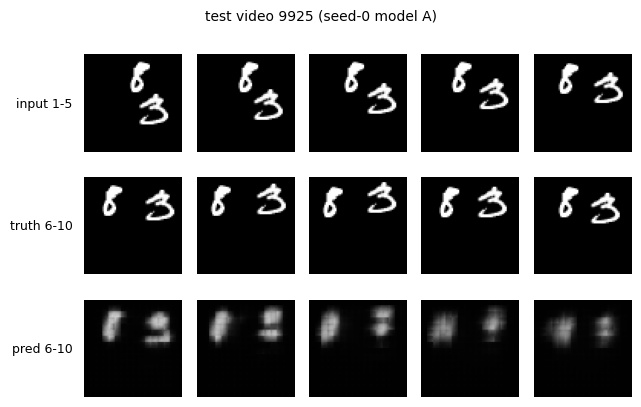

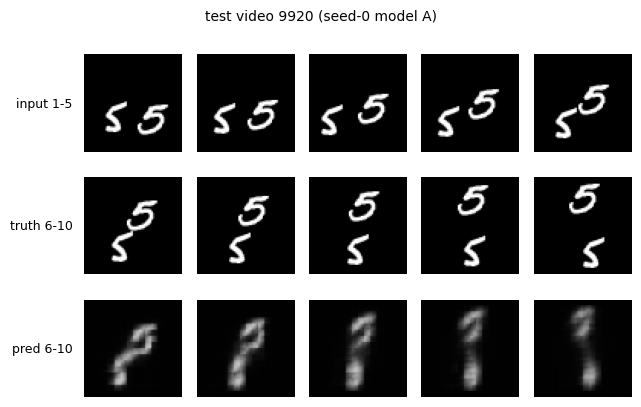

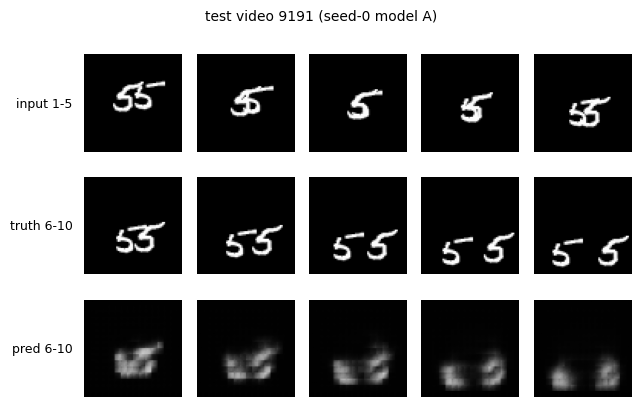

In [13]:
# picking videos for figure 2. when two digits overlap, the bright area of the frame shrinks,
# so a frame whose bright area is well below the video's max is probably an overlap. not perfect,
# so look at the picture and change the indices by hand if needed.
area = (test_vids[:, :10, 0] > 51).sum(dim=(2, 3)).float()           # (1000, 10) frames 1-10
shrink = area.min(1).values / area.max(1).values
overlap_vid = int(torch.argmin(shrink).item())                    # strongest overlap
clean = torch.argsort(shrink, descending=True)[:2].tolist()     # the two with the least overlap
fig2_vids = clean + [overlap_vid]
print('figure 2 test videos (index inside the test split):', fig2_vids)


def show_rows(rows, row_names, title, path):
    # rows: list of tensors (n_frames, 1, 64, 64), one per row
    ncol = max(len(r) for r in rows)
    fig, ax = plt.subplots(len(rows), ncol, figsize=(1.3 * ncol, 1.4 * len(rows)))
    for i, r in enumerate(rows):
        for j in range(ncol):
            a = ax[i, j]
            a.axis('off')
            if j < len(r):
                a.imshow(r[j, 0].numpy(), cmap='gray', vmin=0, vmax=1)
        ax[i, 0].text(-8, 32, row_names[i], ha='right', va='center', fontsize=9)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches='tight')
    plt.show()


mA0, _ = load_model('A', model_A, 0)
for v in fig2_vids:
    pred = predict(mA0, Xt[v:v + 1])[0]
    show_rows([Xt[v], Yt[v], pred], ['input 1-5', 'truth 6-10', 'pred 6-10'],
              f'test video {9000 + v} (seed-0 model A)', f'{OUT}/figs/fig2_vid{9000 + v}.png')

## 3. Testing the Baseline
Everything here runs on the 1000 test videos with t = 1.
C_T = MSE(f(T(X)), T(f(X)))  -> is the model consistent?
E_T = MSE(f(T(X)), T(Y))     -> is it right on the transformed video?
The same function is reused for models B, C, D and the symmetrised ones later.

In [14]:
MIRROR, ROT = (1, 0), (0, 1)     # M and R as group elements


def sym_eval(model, X=None, Y=None):
    # returns the averages and the per-video values (needed for figures 3 and 4)
    if X is None:
        X, Y, _ = test_windows(1, 1)
    fX = predict(model, X)
    out = {'E5': per_video_mse(fX, Y).mean().item()}
    per_vid = {}
    for nm, g in (('M', MIRROR), ('R', ROT)):
        fTX = predict(model, apply_g(X, g))
        C = per_video_mse(fTX, apply_g(fX, g)).mean(1)        # (1000,)
        E = per_video_mse(fTX, apply_g(Y, g)).mean(1)
        out['C' + nm], out['E' + nm] = C.mean().item(), E.mean().item()
        per_vid['C' + nm] = C
    return out, per_vid


def speed_eval(model):
    out = {}
    for k in (1, 2, 3):
        X, Y, mask = test_windows(1, k)
        mse = per_video_mse(predict(model, X), Y)
        out[f'E2_{k}x'] = mse[:, :2].mean().item()           # first two horizons always exist
        if k < 3:
            out[f'E5_{k}x'] = mse.mean().item()              # at 3x only 2 targets exist
    return out


def fmt_row(vals):
    # vals is a list (one per seed) or a single number for blank / copy-last
    if isinstance(vals, list):
        return mean_seeds(vals)
    return sig3(vals)

### Table 3 (mirror and rotation)

In [15]:
t3 = {}
pv_A0 = None
for seed in (0, 1):
    mA, _ = load_model('A', model_A, seed)
    o, pv = sym_eval(mA, Xt, Yt)
    t3.setdefault('A', []).append(o)
    if seed == 0:
        pv_A0 = pv
for nm, m in (('Blank', Blank()), ('Copy-last', CopyLast())):
    t3[nm] = sym_eval(m, Xt, Yt)[0]
results['table3'] = t3
json.dump(results, open(res_path, 'w'), indent=1)

cols = ['E5', 'CM', 'EM', 'CR', 'ER']
print(f'{"model":10}' + ''.join(f'{c:>32}' for c in cols))
print(f'{"A":10}' + ''.join(f'{fmt_row([r[c] for r in t3["A"]]):>32}' for c in cols))
for nm in ('Blank', 'Copy-last'):
    print(f'{nm:10}' + ''.join(f'{fmt_row(t3[nm][c]):>32}' for c in cols))

model                                   E5                              CM                              EM                              CR                              ER
A                  0.0222 (0.0232, 0.0211)      0.00178 (0.00151, 0.00205)         0.0228 (0.0237, 0.0219)      0.00341 (0.00294, 0.00388)          0.024 (0.0247, 0.0234)
Blank                               0.0426                               0                          0.0426                               0                          0.0426
Copy-last                           0.0641                               0                          0.0641                               0                          0.0641


### Figure 3 and the GIFs
Top two videos by per-video C_M (with T = M) and top two by C_R (with T = R), seed-0 model A.
Rows: (1) X | f(X), (2) T(X) | T(Y), (3) T(X) | f(T(X)), (4) T(X) | T(f(X)).

figure 3 videos: [(9347, 'M'), (9269, 'M'), (9279, 'R'), (9768, 'R')]


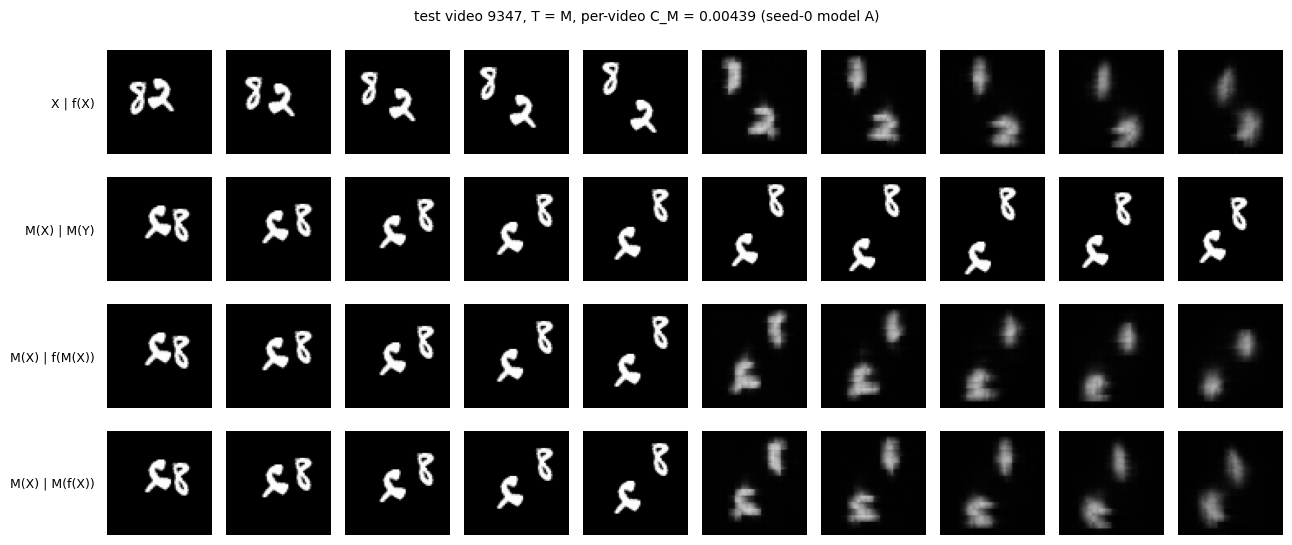

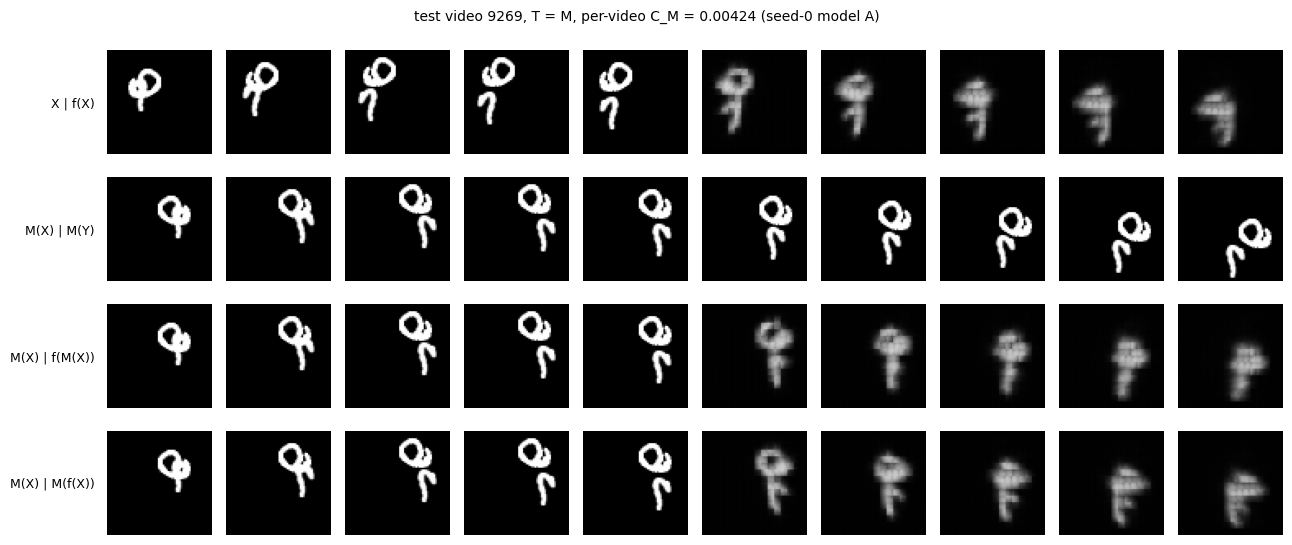

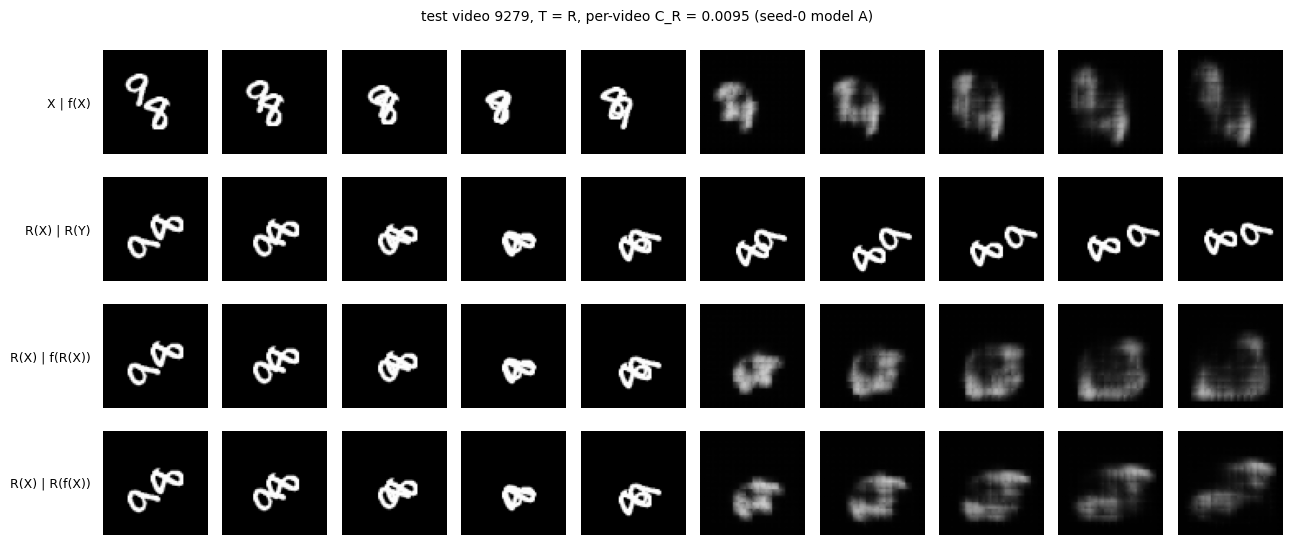

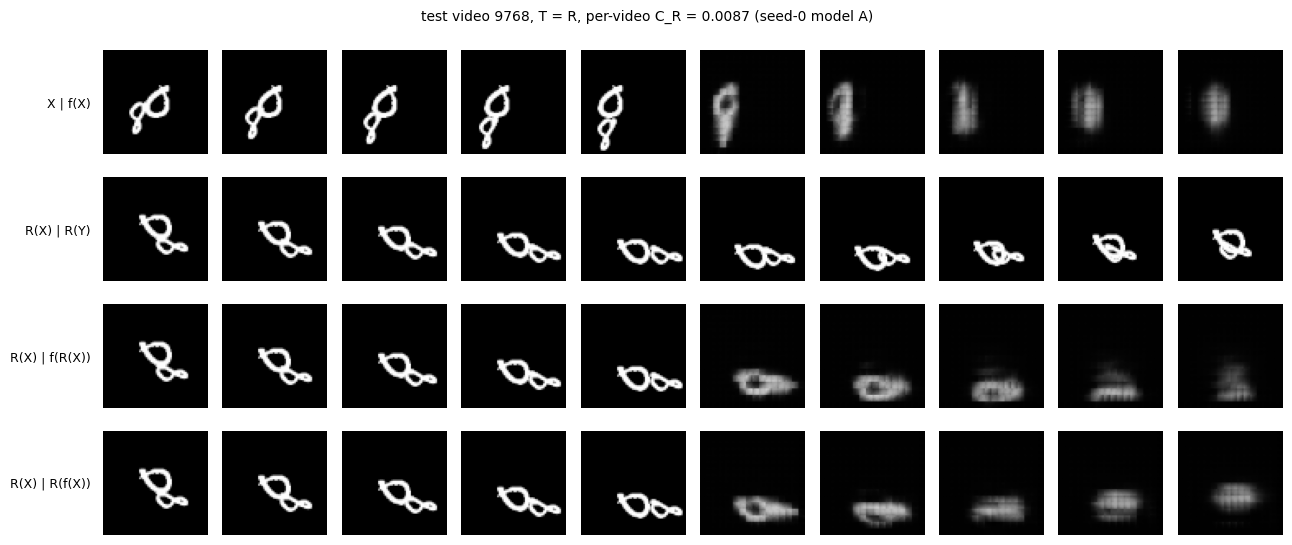

gifs: ['/content/drive/MyDrive/ai651_q2/gifs/fig3_A_vid9347_M.gif', '/content/drive/MyDrive/ai651_q2/gifs/fig3_A_vid9269_M.gif', '/content/drive/MyDrive/ai651_q2/gifs/fig3_A_vid9279_R.gif', '/content/drive/MyDrive/ai651_q2/gifs/fig3_A_vid9768_R.gif']


In [16]:
from PIL import Image, ImageDraw

top_M = torch.argsort(pv_A0['CM'], descending=True)[:2].tolist()
top_R = torch.argsort(pv_A0['CR'], descending=True)[:2].tolist()
fig3_list = [(v, 'M') for v in top_M] + [(v, 'R') for v in top_R]
print('figure 3 videos:', [(9000 + v, T) for v, T in fig3_list])


def four_rows(model, v, T):
    g = MIRROR if T == 'M' else ROT
    X, Y = Xt[v:v + 1], Yt[v:v + 1]
    fX = predict(model, X)
    TX = apply_g(X, g)
    fTX = predict(model, TX)
    rows = [torch.cat([X, fX], 1)[0], torch.cat([TX, apply_g(Y, g)], 1)[0],
            torch.cat([TX, fTX], 1)[0], torch.cat([TX, apply_g(fX, g)], 1)[0]]
    names = ['X | f(X)', f'{T}(X) | {T}(Y)', f'{T}(X) | f({T}(X))', f'{T}(X) | {T}(f(X))']
    return rows, names


def save_gif(rows, names, path, scale=3):
    # one gif frame per forecast horizon. each frame: the 4 rows, left = last input frame, right = horizon h
    S = 64 * scale
    frames = []
    for h in range(5):
        canvas = Image.new('L', (170 + 2 * S + 10, 24 + 4 * (S + 6)), 255)
        d = ImageDraw.Draw(canvas)
        d.text((170, 4), f'input frame 5          forecast h = {h + 1}', fill=0)
        for i, r in enumerate(rows):
            y0 = 24 + i * (S + 6)
            for j, fr in enumerate((r[4], r[5 + h])):
                im = Image.fromarray((fr[0].clamp(0, 1).numpy() * 255).astype(np.uint8)).resize((S, S), Image.NEAREST)
                canvas.paste(im, (170 + j * (S + 6), y0))
            d.text((6, y0 + S // 2), names[i], fill=0)
        frames.append(canvas)
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=700, loop=0)


mA0, _ = load_model('A', model_A, 0)
gif_paths = []
for v, T in fig3_list:
    rows, names = four_rows(mA0, v, T)
    val = pv_A0['C' + T][v].item()
    show_rows(rows, names, f'test video {9000 + v}, T = {T}, per-video C_{T} = {val:.3g} (seed-0 model A)',
              f'{OUT}/figs/fig3_vid{9000 + v}_{T}.png')
    gp = f'{OUT}/gifs/fig3_A_vid{9000 + v}_{T}.gif'
    save_gif(rows, names, gp)
    gif_paths.append(gp)
print('gifs:', gif_paths)

### Figure 4 (per-video consistency gaps)

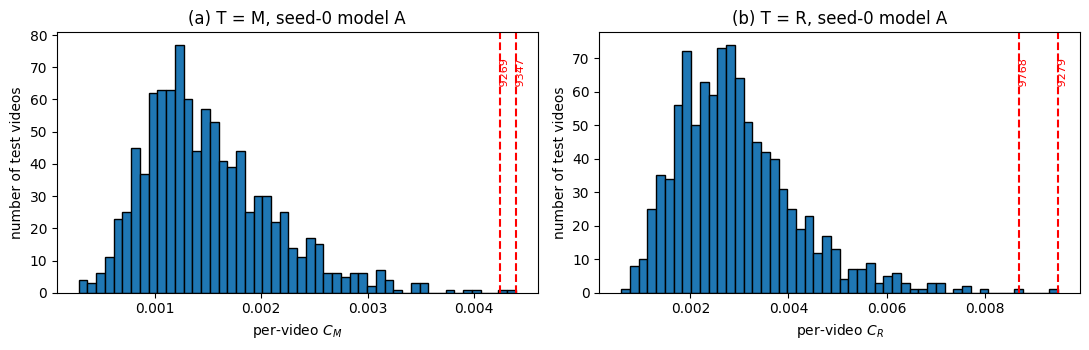

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, T, top in ((ax[0], 'M', top_M), (ax[1], 'R', top_R)):
    vals = pv_A0['C' + T].numpy()
    a.hist(vals, bins=50, color='tab:blue', edgecolor='k')
    for v in top:
        a.axvline(vals[v], color='r', ls='--')
        a.text(vals[v], a.get_ylim()[1] * 0.9, f' {9000 + v}', color='r', fontsize=8, rotation=90, va='top')
    a.set_xlabel(f'per-video $C_{T}$')
    a.set_ylabel('number of test videos')
    a.set_title(f'({"a" if T == "M" else "b"}) T = {T}, seed-0 model A')
plt.tight_layout()
plt.savefig(f'{OUT}/figs/fig4_hist.png', dpi=150)
plt.show()

### Table 4 and Figure 5 (faster motion)

In [18]:
t4 = {'A': [speed_eval(load_model('A', model_A, s)[0]) for s in (0, 1)],
      'Copy-last': speed_eval(CopyLast())}
results['table4'] = t4
json.dump(results, open(res_path, 'w'), indent=1)

cols4 = ['E2_1x', 'E2_2x', 'E2_3x', 'E5_1x', 'E5_2x']
print(f'{"model":10}' + ''.join(f'{c:>32}' for c in cols4))
print(f'{"A":10}' + ''.join(f'{fmt_row([r[c] for r in t4["A"]]):>32}' for c in cols4))
print(f'{"Copy-last":10}' + ''.join(f'{fmt_row(t4["Copy-last"][c]):>32}' for c in cols4))

model                                E2_1x                           E2_2x                           E2_3x                           E5_1x                           E5_2x
A                  0.0186 (0.0195, 0.0177)           0.043 (0.043, 0.0431)           0.0482 (0.05, 0.0464)         0.0222 (0.0232, 0.0211)         0.0465 (0.0462, 0.0467)
Copy-last                           0.0548                          0.0661                          0.0703                          0.0641                          0.0719


figure 5 test video: 9021  frames checked: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 16, 19]


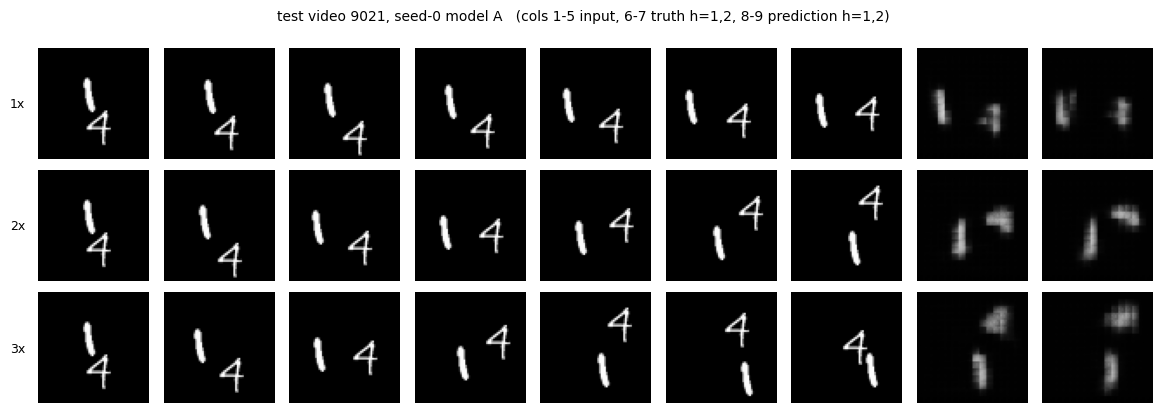

In [19]:
# figure 5 needs a video where the digits don't overlap in any shown true frame.
# shown frames: inputs + first two targets at 1x, 2x and 3x
shown = sorted(set(sum([window_frames(1, k)[0] + window_frames(1, k)[1][:2] for k in (1, 2, 3)], [])))
ar = (test_vids[:, [f - 1 for f in shown], 0] > 51).sum(dim=(2, 3)).float()
ratio = ar.min(1).values / ar.max(1).values
fig5_vid = int(torch.argmax(ratio).item())
print('figure 5 test video:', 9000 + fig5_vid, ' frames checked:', shown)


def speed_panel(model, v, title, path):
    rows, names = [], []
    for k in (1, 2, 3):
        X, Y, _ = batch_windows(test_vids[v:v + 1], [1], [k])
        p = predict(model, X)
        rows.append(torch.cat([X[0], Y[0, :2], p[0, :2]], 0))
        names.append(f'{k}x')
    show_rows(rows, names, title + '   (cols 1-5 input, 6-7 truth h=1,2, 8-9 prediction h=1,2)', path)


speed_panel(mA0, fig5_vid, f'test video {9000 + fig5_vid}, seed-0 model A', f'{OUT}/figs/fig5_A.png')